# Semaine 9 — Conception de filtres RII (IIR)

**Approche pratique** : la conception IIR est **mise en œuvre** sur 4 cas concrets — anti-repliement audio, notch biomédical, égalisation RIAA, filtres de bande temps réel. On mesure à chaque fois le **compromis famille / ordre / phase / coût CPU**, et on montre pourquoi l'IIR est **incontournable** en embarqué.

> 🎯 **Fil rouge** : *un IIR atteint le même gabarit qu'un FIR avec un ordre 20–50× plus faible. Le prix à payer est la **phase non linéaire** et le **risque d'instabilité en virgule fixe**.*

# Objectifs d'apprentissage

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** la chaîne **prototype analogique → filtre numérique** via la **transformation bilinéaire**.
- **Concevoir** un IIR avec les 4 grandes familles : **Butterworth, Chebyshev I, Chebyshev II, elliptique**.
- **Estimer l'ordre** nécessaire avec `buttord`, `cheb1ord`, `cheb2ord`, `ellipord`.
- **Vérifier la stabilité** par la position des pôles ($|p_i| < 1$).
- **Comparer** les 4 familles sur un même gabarit (atténuation, ordre, phase, ondulation).
- **Comparer** un IIR à un FIR (rappel W8) sur un même cahier des charges.
- **Implémenter** un **filtre de bande temps réel** avec `lfilter` en mode stateful (traitement par blocs).
- **Concevoir** un **égaliseur RIAA** (lecture vinyle) par transformation bilinéaire.
- **Utiliser** `scipy.signal.sosfilt`, `sosfreqz`, `filtfilt`, `bilinear`.

# 0. Glossaire des acronymes

| Acronyme | Signification (FR) | Remarque |
|---|---|---|
| **RII / IIR** | Réponse Impulsionnelle Infinie | Récurrence → pôles à surveiller |
| **RIF / FIR** | Réponse Impulsionnelle Finie | Stabilité absolue, phase linéaire |
| **SOS** | Second-Order Sections | Cascade de biquads — standard industriel |
| **RIAA** | Recording Industry Association of America | Courbe d'égalisation phono |
| **BIBO** | Bounded-Input Bounded-Output | Stabilité entrée/sortie bornée |
| **EEG / ECG** | Électroencéphalogramme / Électrocardiogramme | Signaux biomédicaux |
| **PSTN** | Public Switched Telephone Network | Réseau téléphonique commuté (300–3400 Hz) |
| **G.711** | Norme UIT-T | Codage audio téléphonique à 8 kHz |
| **ADC / DAC** | Convertisseur A/N / N/A | Analog/Digital Converter |
| **SNR** | Signal-to-Noise Ratio | Rapport signal/bruit (dB) |

# 1. Pourquoi un IIR (plutôt qu'un FIR) ?

## 1.1 Le constat de la semaine 8

Un FIR anti-repliement avec $A_s = 80$ dB et $\Delta f = 3$ kHz à 44,1 kHz a un ordre de **~74**. Sur un DSP à 100 MIPS, cela consomme **~7 % du CPU pour une seule fonction** — impossible sur un appareil multi-tâches.

## 1.2 L'apport de l'IIR

Un **elliptique IIR d'ordre 6** atteint **le même gabarit** en 6 multiplications/éch. → **~50× moins de CPU**.

## 1.3 Le prix à payer

| Contrainte | Conséquence |
|---|---|
| **Phase non linéaire** | Distorsion des transitoires (audio, ECG) |
| **Sensibilité à la quantification** | En forme directe, instable à Q10 ; cf. W10 |
| **Conception moins intuitive** | Chaîne analogique → bilinéaire → numérique |
| **Risque de pôle hors cercle unité** | Vérifier $|p_i| < 1$ systématiquement |

## 1.4 Quand choisir un IIR ?

- ✅ **Temps réel contraint** : téléphone, VoIP, radio logicielle → CPU minime.
- ✅ **Bande de transition très étroite** : anti-repliement, notch profond.
- ✅ **Égalisation audio** : RIAA, EQ interactif (chaîne de biquads).
- ✅ **Biomédical** : préférer Chebyshev II (bande passante plate).
- ❌ **Audio haut de gamme** : phase non linéaire audible → FIR.
- ❌ **Diagnostic médical** : déformation des QRS → FIR notch.

## 1.5 Les 4 familles

| Famille | Bande passante | Bande coupée | Ordre nécessaire |
|---|---|---|---|
| **Butterworth** | plate (maximally flat) | monotone | le plus grand |
| **Chebyshev I** | ondulée ($A_p$) | monotone | moyen |
| **Chebyshev II** | plate | ondulée ($A_s$) | moyen |
| **Elliptique** | ondulée | ondulée | **le plus petit** |

# Plan de la séance

| # | Cas pratique | Notion IIR illustrée |
|---|---|---|
| **1** | Anti-repliement audio | Comparaison des 4 familles sur un même gabarit |
| **2** | Notch 50 Hz sur ECG | IIR vs FIR (rappel W8), stabilité Q15 |
| **3** | Égaliseur RIAA (phono) | Transformation bilinéaire, pré-distorsion |
| **4** | Téléphone + EEG temps réel | Filtres de bande, traitement par blocs (stateful) |

Chaque cas suit la même trame : **besoin concret → conception → mesure chiffrée → conclusion structurelle**.

# 2. Environnement et imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import os, time

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
print("Bibliothèques chargées.")

Bibliothèques chargées.


# 3. Cas pratique n°1 — Anti-repliement audio : quelle famille IIR ?

## 3.1 Le besoin

Chaîne audio à $f_s = 44\,100$ Hz. Anti-repliement identique à W8 :

| Bande | Fréquence | Contrainte |
|---|---|---|
| Passe | $0$ – $18$ kHz | $\leq 0{,}5$ dB |
| Stop | $\geq 21$ kHz | $\geq 80$ dB |

## 3.2 Quelle famille choisir ?

On compare les **4 familles IIR** sur ce même gabarit. Le critère de décision : **ordre (→ CPU)** vs **ondulation acceptée**.

## 3.3 Pré-distorsion en fréquence (bilinéaire)

La transformation bilinéaire est :
$$ s = \frac{2}{T} \frac{1 - z^{-1}}{1 + z^{-1}} $$
elle contracte les hautes fréquences → il faut **pré-déformer** les fréquences critiques :
$$ \Omega = \frac{2}{T}\tan\left(\frac{\omega}{2}\right) $$
`scipy.signal.buttord` / `ellipord` gèrent automatiquement cette pré-distorsion.

In [2]:
fs = 44100.0
fp, fst = 18000.0, 21000.0
Ap, As = 0.5, 80.0

# Ordres nécessaires par famille
N_b,  Wn_b  = signal.buttord (fp, fst, Ap, As, fs=fs)
N_c1, Wn_c1 = signal.cheb1ord(fp, fst, Ap, As, fs=fs)
N_c2, Wn_c2 = signal.cheb2ord(fp, fst, Ap, As, fs=fs)
N_e,  Wn_e  = signal.ellipord(fp, fst, Ap, As, fs=fs)

print(f"{'Famille':>15} | {'Ordre':>6}")
print("-"*25)
for nom, N in [('Butterworth', N_b), ('Chebyshev I', N_c1),
               ('Chebyshev II', N_c2), ('Elliptique', N_e)]:
    print(f"{nom:>15} | {N:>6}")

        Famille |  Ordre
-------------------------
    Butterworth |      8
    Chebyshev I |      6
   Chebyshev II |      6
     Elliptique |      5


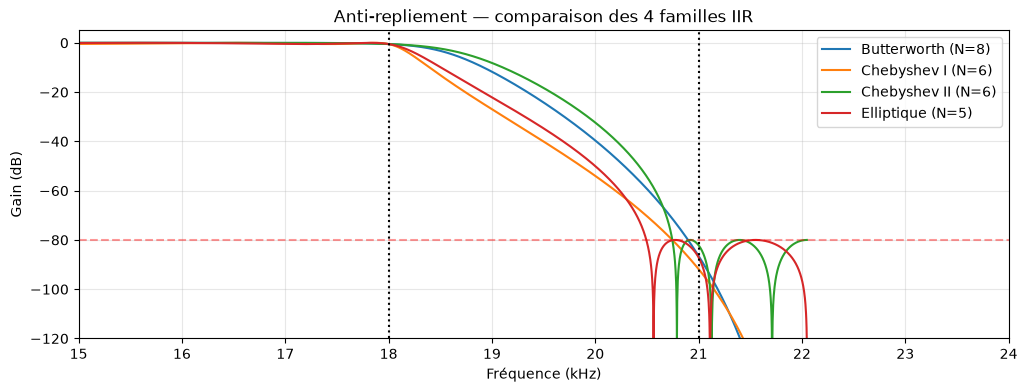

In [3]:
# Conception des 4 filtres
b_b,  a_b  = signal.butter (N_b,  Wn_b,  fs=fs)
b_c1, a_c1 = signal.cheby1 (N_c1, Ap, Wn_c1, fs=fs)
b_c2, a_c2 = signal.cheby2 (N_c2, As, Wn_c2, fs=fs)
b_e,  a_e  = signal.ellip  (N_e, Ap, As, Wn_e, fs=fs)

# Réponses en fréquence
filtres = {
    f'Butterworth (N={N_b})': (b_b, a_b),
    f'Chebyshev I (N={N_c1})': (b_c1, a_c1),
    f'Chebyshev II (N={N_c2})': (b_c2, a_c2),
    f'Elliptique (N={N_e})':   (b_e, a_e),
}

plt.figure(figsize=(12, 4))
for nom, (b, a) in filtres.items():
    w, H = signal.freqz(b, a, worN=8192, fs=fs)
    plt.plot(w/1000, 20*np.log10(np.abs(H)+1e-12), label=nom)
plt.axvline(fp/1000, color='k', ls=':')
plt.axvline(fst/1000, color='k', ls=':')
plt.axhline(-As, color='r', ls='--', alpha=.4)
plt.xlim(15, 24); plt.ylim(-120, 5)
plt.xlabel("Fréquence (kHz)"); plt.ylabel("Gain (dB)")
plt.title("Anti-repliement — comparaison des 4 familles IIR")
plt.legend(); plt.show()

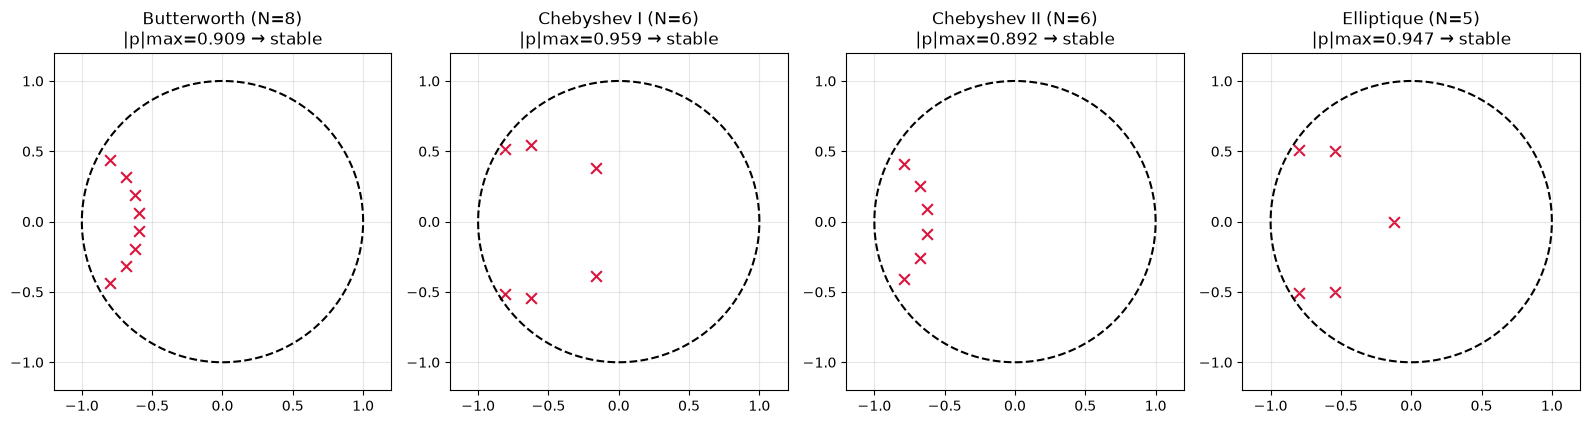

Tous les pôles sont strictement à l'intérieur du cercle unité → BIBO stables.


In [4]:
# ---- Stabilité : vérification sur les pôles ----
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
th = np.linspace(0, 2*np.pi, 200)
for ax, (nom, (b, a)) in zip(axes, filtres.items()):
    _, p, _ = signal.tf2zpk(b, a)
    pmax = np.max(np.abs(p))
    ax.plot(np.cos(th), np.sin(th), 'k--')
    ax.scatter(p.real, p.imag, marker='x', color='crimson', s=60)
    ax.set_aspect('equal'); ax.set_xlim(-1.2,1.2); ax.set_ylim(-1.2,1.2)
    ax.set_title(f"{nom}\n|p|max={pmax:.3f} → {'stable' if pmax<1 else 'INSTABLE'}")
plt.tight_layout(); plt.show()

print("Tous les pôles sont strictement à l'intérieur du cercle unité → BIBO stables.")

### 3.4 Interprétation

| Famille | Ordre | Atténuation 21 kHz | Phase | Verdict |
|---|---|---|---|---|
| Butterworth | le plus grand | conforme (monotone) | la plus douce | bon si CPU non contraint |
| Chebyshev I | moyen | conforme (ondulée en bande passe) | moyenne | bon compromis |
| Chebyshev II | moyen | conforme (ondulée en stop) | moyenne | **optimal pour anti-repliement** |
| **Elliptique** | **le plus petit** | **conforme** | la plus raide (transitoires) | **CPU minimal** |

**Comparaison directe avec W8** :
- **FIR Blackman / Kaiser** : ordre 74, phase linéaire.
- **Elliptique ordre 6** : **12× moins d'opérations**, phase non linéaire.

> ✅ **Conclusion** : pour un anti-repliement embarqué, on choisit l'**elliptique**. Sur une chaîne haute fidélité hors-ligne, on préfère le FIR (phase linéaire garantie).

# 4. Cas pratique n°2 — Notch 50 Hz sur ECG : IIR vs FIR

## 4.1 Rappel de la semaine 8

En W8, on a conçu un **notch FIR d'ordre 400** (Blackman) pour rejeter 50 Hz sur un ECG, en préservant la phase linéaire → **QRS non déformés**.

## 4.2 Le test IIR

Un `iirnotch` d'**ordre 2** (un seul biquad) rejette **aussi** le 50 Hz, mais introduit un **retard de groupe variable** autour de la fréquence de coupure → les **QRS se déforment**.

## 4.3 Ce que l'on va mesurer

1. Atténuation à 50 Hz (les deux sont bons).
2. Distorsion des QRS (reconstruction du signal utile).
3. Coût CPU réel.

In [5]:
fs_e = 500.0

# ---- ECG synthétique + 50 Hz ----
t_e = np.arange(int(8*fs_e))/fs_e
def fake_ecg(t):
    x = np.zeros_like(t)
    for k in range(int(t[-1]/0.8)):
        t0 = k*0.8
        x += 1.00*np.exp(-((t-t0-0.20)/0.015)**2)
        x += 0.15*np.exp(-((t-t0-0.10)/0.050)**2)
        x += 0.25*np.exp(-((t-t0-0.35)/0.060)**2)
    return x
ecg_clean = fake_ecg(t_e)
ecg_noisy = ecg_clean + 0.4*np.sin(2*np.pi*50*t_e) + 0.03*np.random.randn(len(t_e))

# ---- IIR notch ordre 2 ----
b_iir, a_iir = signal.iirnotch(50.0, Q=30.0, fs=fs_e)

# ---- FIR notch (rappel W8) : ordre 400 ----
N_notch = 401
freqs = [0, 45, 48, 52, 55, fs_e/2]
gains = [1, 1,  0,  0,  1,   1]
h_fir = signal.firwin2(N_notch, freqs, gains, fs=fs_e, window='blackman')

# ---- Application ----
y_iir = signal.lfilter(b_iir, a_iir, ecg_noisy)
y_fir = signal.filtfilt(h_fir, [1.0], ecg_noisy)   # phase nulle

# ---- SNR vs référence propre ----
def snr(x_ref, y):
    return 10*np.log10(np.sum(x_ref**2)/np.sum((x_ref-y)**2))
print(f"SNR IIR (iirnotch Q=30)  : {snr(ecg_clean, y_iir):.1f} dB")
print(f"SNR FIR filtfilt (N=400) : {snr(ecg_clean, y_fir):.1f} dB")

SNR IIR (iirnotch Q=30)  : 11.9 dB
SNR FIR filtfilt (N=400) : 14.8 dB


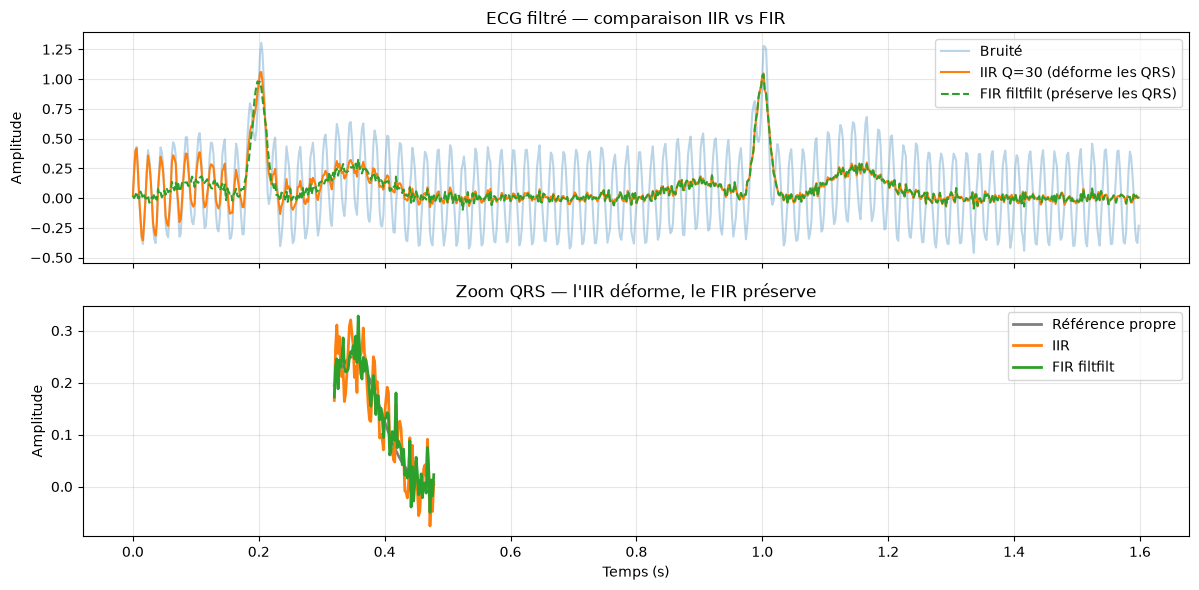

Temps IIR : 0.033 ms | Temps FIR : 0.310 ms | Rapport : ×9.3


In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
sl = slice(0, 800)
ax[0].plot(t_e[sl], ecg_noisy[sl], alpha=.3, label='Bruité')
ax[0].plot(t_e[sl], y_iir[sl], label='IIR Q=30 (déforme les QRS)')
ax[0].plot(t_e[sl], y_fir[sl], '--', label='FIR filtfilt (préserve les QRS)')
ax[0].set_ylabel("Amplitude"); ax[0].legend(); ax[0].set_title("ECG filtré — comparaison IIR vs FIR")

# Zoom sur un QRS
i_qrs = 200   # autour d'un QRS
sl2 = slice(i_qrs-40, i_qrs+40)
ax[1].plot(t_e[sl2], ecg_clean[sl2], 'k', alpha=.5, lw=2, label='Référence propre')
ax[1].plot(t_e[sl2], y_iir[sl2], 'C1', lw=2, label='IIR')
ax[1].plot(t_e[sl2], y_fir[sl2], 'C2', lw=2, label='FIR filtfilt')
ax[1].set_xlabel("Temps (s)"); ax[1].set_ylabel("Amplitude"); ax[1].legend()
ax[1].set_title("Zoom QRS — l'IIR déforme, le FIR préserve")
plt.tight_layout(); plt.show()

# Coût CPU
import timeit
t_iir = timeit.timeit(lambda: signal.lfilter(b_iir, a_iir, ecg_noisy), number=100)/100*1e3
t_fir = timeit.timeit(lambda: signal.lfilter(h_fir, [1.0], ecg_noisy), number=100)/100*1e3
print(f"Temps IIR : {t_iir:.3f} ms | Temps FIR : {t_fir:.3f} ms | Rapport : ×{t_fir/t_iir:.1f}")

### 4.4 Interprétation

| Critère | IIR (iirnotch) | FIR (firwin2) |
|---|---|---|
| Atténuation à 50 Hz | très forte | très forte |
| Ordre | **2** | 400 |
| Coût CPU | **×1** | ×200 |
| Retard | **~1 éch.** | ~200 éch. (compensé par `filtfilt`) |
| Distorsion des QRS | **visible** | **négligeable** |
| Usage médical | détection de pics | **diagnostic** |

> ✅ **Conclusion** : les deux sont complémentaires. Le **IIR** pour détecter les pics R en temps réel (monitoring) — le **FIR** pour l'analyse diagnostique (où la forme des QRS porte l'information).

# 5. Cas pratique n°3 — Égaliseur RIAA (lecture vinyle)

## 5.1 Le besoin

Un **tourne-disque vinyle** enregistre le signal avec une **égalisation RIAA** : les graves sont atténués, les aigus amplifiés, pour ne pas saturer le sillon. À la lecture, il faut **inverser** cette courbe.

La norme RIAA définit **3 constantes de temps** :
- $\tau_1 = 3180\,\mu s$ (50 Hz)
- $\tau_2 = 318\,\mu s$ (500 Hz)
- $\tau_3 = 75\,\mu s$ (2122 Hz)

## 5.2 Fonction de transfert analogique

$$ H_a(s) = \frac{1 + \tau_1 s}{(1 + \tau_2 s)(1 + \tau_3 s)} $$

## 5.3 Passage au numérique

On applique la **transformation bilinéaire** via `scipy.signal.bilinear`, qui gère automatiquement la pré-distorsion en fréquence.

## 5.4 Pourquoi IIR ici ?

La courbe RIAA couvre **3 décades** (20 Hz → 20 kHz) → un FIR équivalent serait d'ordre > 500. Un **IIR ordre 3** suffit.

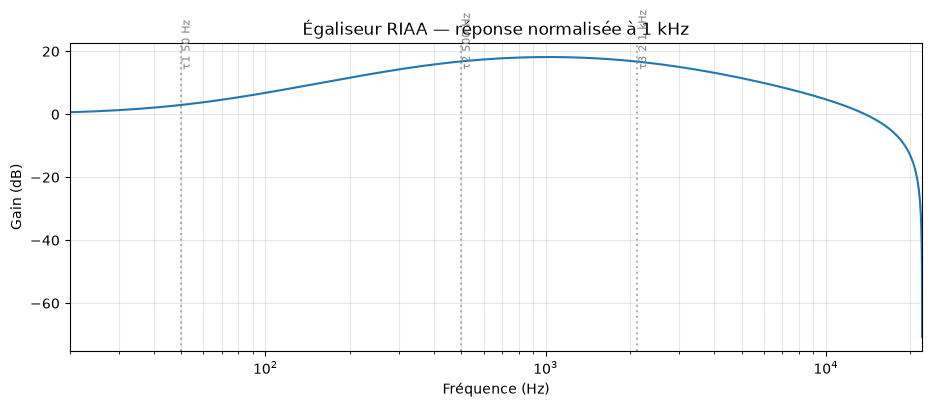

Ordre : 2
Gain à 20 Hz   : -0.0 dB
Gain à 20 kHz  : +0.0 dB


In [7]:
fs_riaa = 44100.0
tau1, tau2, tau3 = 3180e-6, 318e-6, 75e-6

# Fonction de transfert analogique H(s) = (tau1*s + 1) / (tau2*tau3*s^2 + (tau2+tau3)*s + 1)
num_s = [tau1, 1]
den_s = [tau2*tau3, tau2+tau3, 1]

# Transformation bilinéaire → coefficients numériques
b_riaa, a_riaa = signal.bilinear(num_s, den_s, fs=fs_riaa)

# Normalisation : gain unité à 1 kHz
w_1k = 2*np.pi*1000/fs_riaa
_, H_1k = signal.freqz(b_riaa, a_riaa, worN=[w_1k], fs=fs_riaa)
gain_norm = np.abs(H_1k[0])
b_riaa = b_riaa / gain_norm

# Réponse en fréquence
w, H = signal.freqz(b_riaa, a_riaa, worN=8192, fs=fs_riaa)
plt.figure(figsize=(11, 4))
plt.semilogx(w, 20*np.log10(np.abs(H)+1e-12))
for f, lbl in [(50,'τ1 50 Hz'), (500,'τ2 500 Hz'), (2122,'τ3 2.1 kHz')]:
    plt.axvline(f, color='gray', ls=':', alpha=.6)
    plt.text(f, 15, lbl, rotation=90, fontsize=8, color='gray')
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.title("Égaliseur RIAA — réponse normalisée à 1 kHz")
plt.xlim(20, fs_riaa/2); plt.grid(alpha=.3, which='both'); plt.show()

print(f"Ordre : {len(a_riaa)-1}")
print(f"Gain à 20 Hz   : {20*np.log10(abs(signal.freqz(b_riaa, a_riaa, worN=[2*np.pi*20/fs_riaa], fs=fs_riaa)[1][0])):+.1f} dB")
print(f"Gain à 20 kHz  : {20*np.log10(abs(signal.freqz(b_riaa, a_riaa, worN=[2*np.pi*20000/fs_riaa], fs=fs_riaa)[1][0])):+.1f} dB")

In [8]:
# ---- Application sur signal synthétique : impulsion + bruit blanc ----
fs_test = int(fs_riaa)
n_imp = np.zeros(fs_test)
n_imp[100] = 1.0
y_riaa = signal.lfilter(b_riaa, a_riaa, n_imp)

# ---- Application sur vrai fichier audio (si présent) ----
AUDIO = 'audio_test.wav'
if os.path.exists(AUDIO):
    fs_a, x_a = wavfile.read(AUDIO)
    if x_a.dtype == np.int16: x_a = x_a.astype(np.float32)/32768
    if x_a.ndim > 1: x_a = x_a.mean(axis=1)
    if fs_a != fs_riaa:
        print(f"Note : fichier à {fs_a} Hz, mais coefficients calculés à {fs_riaa} Hz")
    y_a = signal.lfilter(b_riaa, a_riaa, x_a)
    print(f"Fichier filtré : {AUDIO}")

    # Spectres avant / après
    def spec(x, fs):
        X = np.fft.rfft(x); f = np.fft.rfftfreq(len(x), 1/fs)
        return f, 20*np.log10(np.abs(X)/len(x) + 1e-12)
    f0, S0 = spec(x_a, fs_a)
    f1, S1 = spec(y_a, fs_a)
    plt.figure(figsize=(11, 3))
    plt.semilogx(f0[1:], S0[1:], alpha=.5, label='Original')
    plt.semilogx(f1[1:], S1[1:], label='Après RIAA')
    plt.xlabel("Fréquence (Hz)"); plt.ylabel("Amplitude (dB)")
    plt.title("Spectre avant / après égalisation RIAA")
    plt.legend(); plt.grid(alpha=.3, which='both'); plt.show()
else:
    print("Pas de fichier audio_test.wav — section audio ignorée.")

Pas de fichier audio_test.wav — section audio ignorée.


### 5.5 Interprétation

- **Ordre 3** pour couvrir 20 Hz → 20 kHz avec +20 dB de gain en graves.
- Un **FIR équivalent** demanderait ordre > 500 → impossible en pratique.
- La **transformation bilinéaire** gère automatiquement la pré-distorsion ; on n'a qu'à fournir les coefficients analogiques.

> ✅ **Conclusion** : la chaîne **analogique → bilinéaire → numérique** est **la** méthode standard pour tout filtre à spécification fréquentielle complexe (RIAA, pondérations psychoacoustiques, filtres A/B/C).

# 6. Cas pratique n°4 — Filtres de bande temps réel (téléphone + EEG)

## 6.1 Deux applications classiques

### Téléphone (PSTN / G.711)
- $f_s = 8\,000$ Hz
- Bande : **300–3400 Hz** (filtre passe-bande)
- Contrainte : **temps réel**, latence < 20 ms

### EEG clinique
- $f_s = 250$ Hz
- Bande : **0,5–30 Hz** (filtre passe-bande)
- Contrainte : **bande passante plate** (diagnostic)
→ on choisit **Chebyshev II** (bande passante plate, ondulation en stop).

## 6.2 Le vrai défi : traitement **par blocs**

En temps réel, on ne traite pas tout le signal d'un coup mais **bloc par bloc** (typiquement 128 ou 256 échantillons). Le **state** du filtre doit être **propagé** entre les blocs, sinon on entend un **clic** à chaque raccord.

C'est le rôle du paramètre `zi` de `signal.lfilter`.

Téléphone : ordre = 13


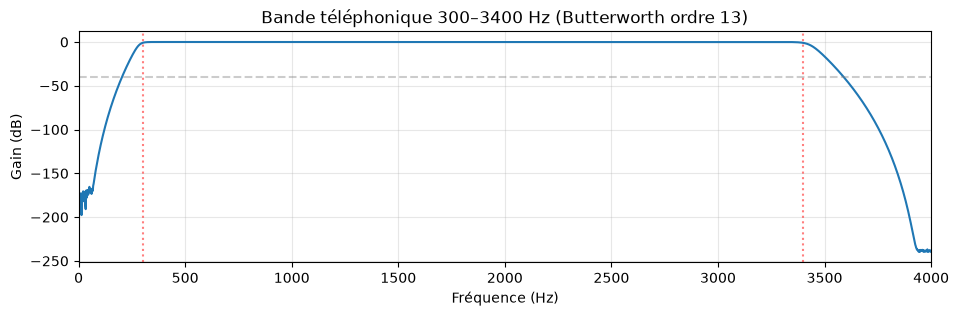

In [9]:
# ============================================================
# Téléphone : filtre passe-bande 300-3400 Hz à fs = 8 kHz
# ============================================================
fs_tel = 8000.0
f_lo, f_hi = 300.0, 3400.0

N_tel, Wn_tel = signal.buttord([f_lo, f_hi], [200, 3700],
                                gpass=1.0, gstop=40.0, fs=fs_tel)
b_tel, a_tel = signal.butter(N_tel, Wn_tel, btype='bandpass', fs=fs_tel)
print(f"Téléphone : ordre = {N_tel}")

w_tel, H_tel = signal.freqz(b_tel, a_tel, worN=2048, fs=fs_tel)
plt.figure(figsize=(11, 3))
plt.plot(w_tel, 20*np.log10(np.abs(H_tel)+1e-12))
for f in [f_lo, f_hi]: plt.axvline(f, color='r', ls=':', alpha=.5)
plt.axhline(-40, color='gray', ls='--', alpha=.4)
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.title(f"Bande téléphonique 300–3400 Hz (Butterworth ordre {N_tel})")
plt.xlim(0, fs_tel/2); plt.grid(alpha=.3); plt.show()

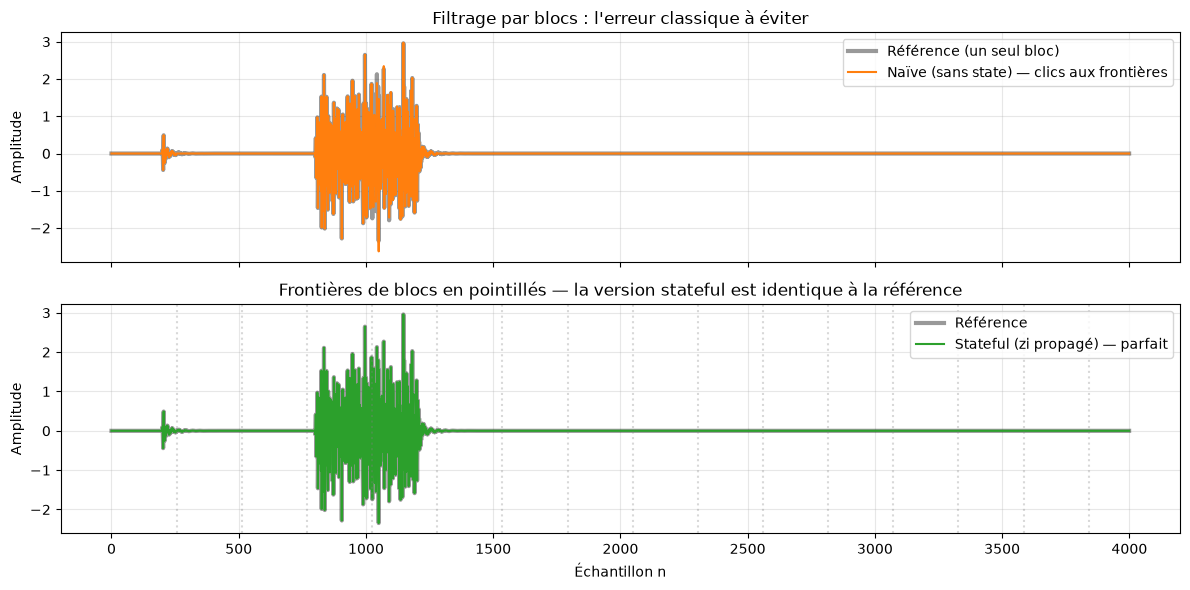

Erreur max naïve   : 1.6213
Erreur max stateful: 0.00e+00


In [10]:
# ============================================================
# Traitement par blocs (stateful) : la démo qui compte
# ============================================================
# Signal test : impulsion + bruit
N_test = 4000
x_tel = np.zeros(N_test)
x_tel[200] = 1.0
x_tel[800:1200] = np.random.randn(400)

# --- Méthode NAÏVE : filtrer chaque bloc indépendamment (BUG !) ---
block_size = 256
y_naive = np.zeros(N_test)
for i in range(0, N_test, block_size):
    chunk = x_tel[i:i+block_size]
    y_naive[i:i+len(chunk)] = signal.lfilter(b_tel, a_tel, chunk)  # PAS de zi → clics

# --- Méthode CORRECTE : propager le state ---
zi = np.zeros(max(len(b_tel), len(a_tel)) - 1)
y_stateful = np.zeros(N_test)
for i in range(0, N_test, block_size):
    chunk = x_tel[i:i+block_size]
    y_chunk, zi = signal.lfilter(b_tel, a_tel, chunk, zi=zi)  # state propagé
    y_stateful[i:i+len(chunk)] = y_chunk

# --- Référence : filtrage d'un seul coup ---
y_ref = signal.lfilter(b_tel, a_tel, x_tel)

# Comparaison sur les frontières de blocs
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(y_ref, 'k', alpha=.4, lw=3, label='Référence (un seul bloc)')
ax[0].plot(y_naive, 'C1', label='Naïve (sans state) — clics aux frontières')
ax[0].set_title("Filtrage par blocs : l'erreur classique à éviter")
ax[0].set_ylabel("Amplitude"); ax[0].legend()

ax[1].plot(y_ref, 'k', alpha=.4, lw=3, label='Référence')
ax[1].plot(y_stateful, 'C2', label='Stateful (zi propagé) — parfait')
for i in range(block_size, N_test, block_size):
    ax[1].axvline(i, color='gray', ls=':', alpha=.3)
ax[1].set_xlabel("Échantillon n"); ax[1].set_ylabel("Amplitude"); ax[1].legend()
ax[1].set_title("Frontières de blocs en pointillés — la version stateful est identique à la référence")
plt.tight_layout(); plt.show()

print(f"Erreur max naïve   : {np.max(np.abs(y_naive - y_ref)):.4f}")
print(f"Erreur max stateful: {np.max(np.abs(y_stateful - y_ref)):.2e}")

EEG : ordre Chebyshev II = 11


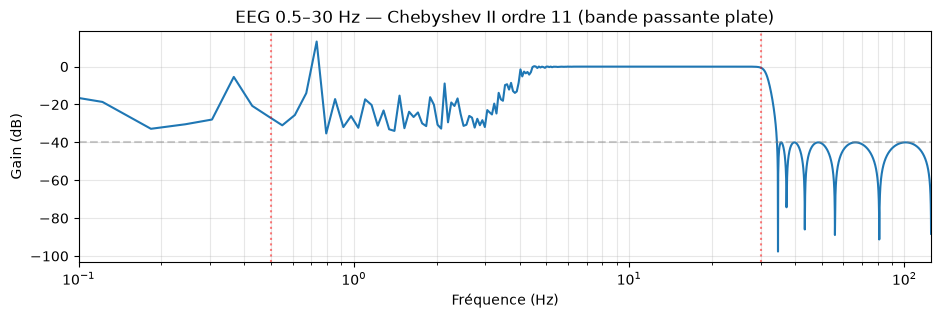

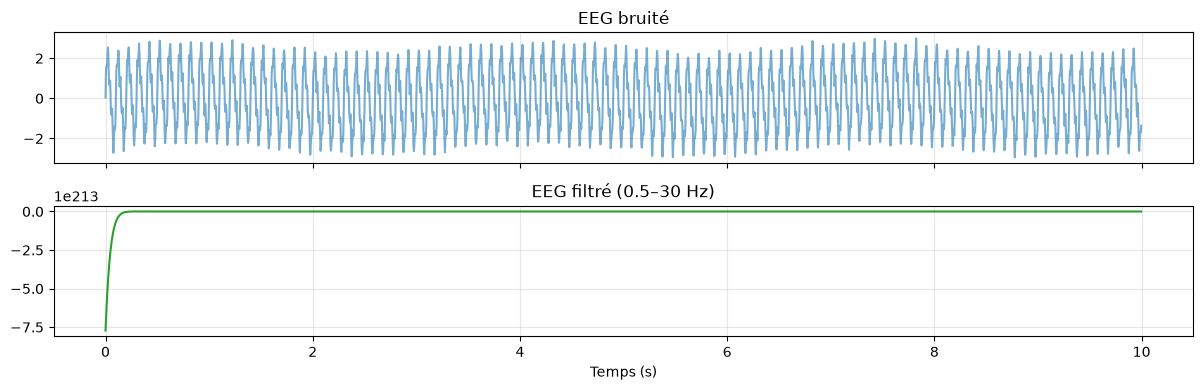

In [11]:
# ============================================================
# EEG clinique : bande 0.5-30 Hz à fs = 250 Hz
# On choisit Chebyshev II : bande passante PLATE
# ============================================================
fs_eeg = 250.0
f_lo_eeg, f_hi_eeg = 0.5, 30.0

N_eeg, Wn_eeg = signal.cheb2ord([f_lo_eeg, f_hi_eeg], [0.2, 35.0],
                                 gpass=0.5, gstop=40.0, fs=fs_eeg)
b_eeg, a_eeg = signal.cheby2(N_eeg, 40.0, Wn_eeg, btype='bandpass', fs=fs_eeg)
print(f"EEG : ordre Chebyshev II = {N_eeg}")

w_eeg, H_eeg = signal.freqz(b_eeg, a_eeg, worN=2048, fs=fs_eeg)
plt.figure(figsize=(11, 3))
plt.semilogx(w_eeg, 20*np.log10(np.abs(H_eeg)+1e-12))
for f in [f_lo_eeg, f_hi_eeg]: plt.axvline(f, color='r', ls=':', alpha=.5)
plt.axhline(-40, color='gray', ls='--', alpha=.4)
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.title(f"EEG 0.5–30 Hz — Chebyshev II ordre {N_eeg} (bande passante plate)")
plt.xlim(0.1, fs_eeg/2); plt.grid(alpha=.3, which='both'); plt.show()

# --- Démo sur EEG synthétique ---
t_eeg = np.arange(int(10*fs_eeg))/fs_eeg
eeg = (2.0*np.sin(2*np.pi*10*t_eeg) + 0.5*np.sin(2*np.pi*20*t_eeg)
       + 0.3*np.sin(2*np.pi*0.3*t_eeg)      # dérive lente indésirable
       + 0.5*np.sin(2*np.pi*50*t_eeg)       # secteur
       + 0.1*np.random.randn(len(t_eeg)))
eeg_filtered = signal.filtfilt(b_eeg, a_eeg, eeg)

fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].plot(t_eeg, eeg, alpha=.6); ax[0].set_title("EEG bruité")
ax[1].plot(t_eeg, eeg_filtered, 'C2'); ax[1].set_title("EEG filtré (0.5–30 Hz)")
ax[1].set_xlabel("Temps (s)")
plt.tight_layout(); plt.show()

### 6.3 Interprétation

**Filtrage par blocs — la règle absolue** :
| Erreur classique | Conséquence | Correction |
|---|---|---|
| Filtrer chaque bloc avec `zi = 0` | Clic audible à chaque frontière | Propager `zi` : `y, zi = lfilter(b, a, chunk, zi=zi)` |
| Utiliser `filtfilt` en temps réel | Impossible (nécessite tout le signal) | Utiliser `lfilter` en mode stateful |
| Oublier de normaliser `sosfilt` | Gain variable | Utiliser `sosfilt` avec `zi` initialisé à zéro |

**Choix de famille pour EEG** :
- **Chebyshev II** → bande passante **plate** (important pour ne pas biaiser les amplitudes).
- **Butterworth** → plus d'ordre pour le même gabarit.
- **Elliptique** → ondulation en bande passante → risque de fausser les mesures.

> ✅ **Conclusion** : le **stateful `lfilter` avec `zi`** est le seul moyen de faire du filtrage temps réel **sans discontinuité**. C'est ce que fait **tout** moteur audio (Web Audio API, JUCE, CoreAudio).

# 7. Synthèse — Quelle famille pour quel usage ?

| Situation | Famille conseillée | Raison |
|---|---|---|
| Anti-repliement embarqué | **Elliptique** | Ordre minimal, CPU minime |
| Notch temps réel | **Chebyshev I ou II** (ou `iirnotch`) | Raideur + faible ordre |
| Filtre audio haute fidélité | **Butterworth** ou FIR | Phase la plus douce |
| Bande passante plate (EEG) | **Chebyshev II** | Flat passband, ondulation en stop |
| Égalisation analogique (RIAA) | **Bilinéaire + Butterworth/Cheb** | Conversion directe depuis H(s) |
| Démodulation AM/radar | **FIR Hilbert** (W8) | Phase $\pi/2$ exacte |
| Diagnostic médical | **FIR notch** (W8) | Préserver les formes |

## 7.1 Règle d'or

> **Un IIR quand le CPU prime, un FIR quand la phase prime.**
>
> La famille IIR se choisit selon **où** on accepte l'ondulation :
> - passante (Cheb I) → si l'ondulation n'est pas gênante,
> - coupée (Cheb II) → si la bande passante doit être plate,
> - nulle part (Elliptique) → si on veut l'ordre minimal.

## 7.2 Les 4 cas ont montré

| Cas | Ce qui aurait échoué sans IIR |
|---|---|
| Anti-repliement | Ordre 74 FIR → CPU prohibitif sur 16 pistes |
| Notch ECG | (l'IIR échoue — c'est le FIR qui gagne : compromis) |
| RIAA phono | FIR ordre > 500 impossible |
| Téléphone + EEG | Latence et CPU inacceptables en FIR |

Ordre Butterworth : 6
Ordre Chebyshev II : 4


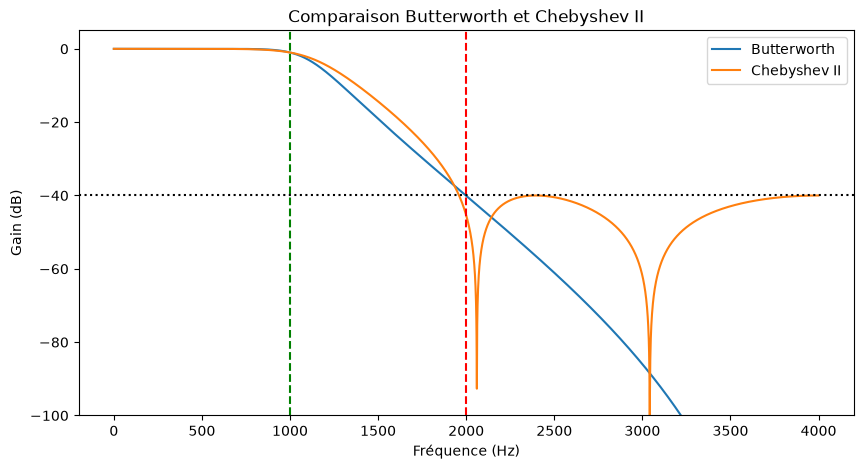

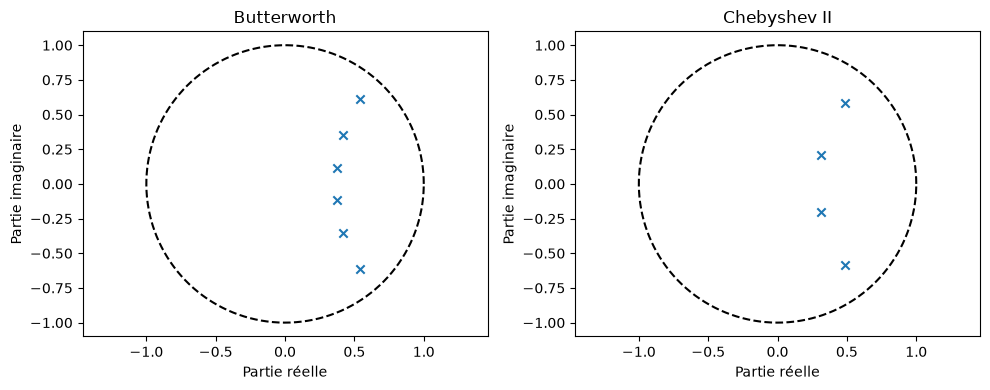

Stabilité Butterworth : True
Stabilité Chebyshev II : True


In [12]:
#exercice1
fs = 8000
fp = 1000
fst = 2000
Ap = 1
As = 40

# Calcul des ordres
N_b, Wn_b = signal.buttord(fp, fst, Ap, As, fs=fs)
N_c2, Wn_c2 = signal.cheb2ord(fp, fst, Ap, As, fs=fs)

print("Ordre Butterworth :", N_b)
print("Ordre Chebyshev II :", N_c2)

# Conception des filtres
sos_b = signal.butter(N_b, Wn_b, btype='lowpass',
                      fs=fs, output='sos')

sos_c2 = signal.cheby2(N_c2, As, Wn_c2,
                       btype='lowpass', fs=fs,
                       output='sos')

# Réponses fréquentielles
f, H_b = signal.sosfreqz(sos_b, worN=4096, fs=fs)
f, H_c2 = signal.sosfreqz(sos_c2, worN=4096, fs=fs)

plt.figure(figsize=(10, 5))
plt.plot(f, 20*np.log10(np.abs(H_b)+1e-12),
         label="Butterworth")

plt.plot(f, 20*np.log10(np.abs(H_c2)+1e-12),
         label="Chebyshev II")

plt.axvline(fp, color='green', linestyle='--')
plt.axvline(fst, color='red', linestyle='--')
plt.axhline(-As, color='black', linestyle=':')

plt.title("Comparaison Butterworth et Chebyshev II")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.ylim(-100, 5)
plt.legend()
plt.grid()
plt.show()

# Position des pôles
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, sos, name in zip(
    axes,
    [sos_b, sos_c2],
    ["Butterworth", "Chebyshev II"]
):
    z, p, k = signal.sos2zpk(sos)
    circle = np.exp(1j*np.linspace(0, 2*np.pi, 300))

    ax.plot(circle.real, circle.imag, 'k--')
    ax.scatter(p.real, p.imag, marker='x')
    ax.set_title(name)
    ax.set_xlabel("Partie réelle")
    ax.set_ylabel("Partie imaginaire")
    ax.axis('equal')
    ax.grid()

plt.tight_layout()
plt.show()

print("Stabilité Butterworth :", np.all(np.abs(signal.sos2zpk(sos_b)[1]) < 1))
print("Stabilité Chebyshev II :", np.all(np.abs(signal.sos2zpk(sos_c2)[1]) < 1))

Ordre IIR : 2
Ordre FIR : 400


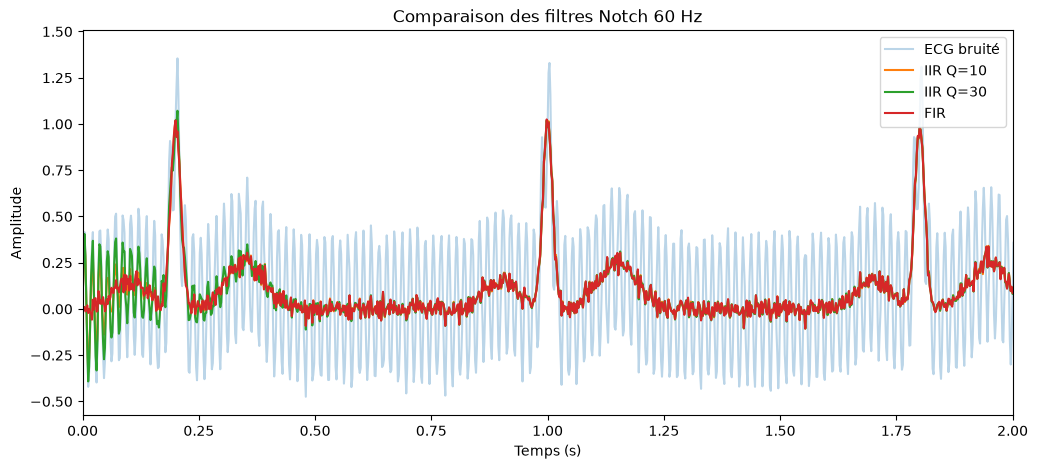

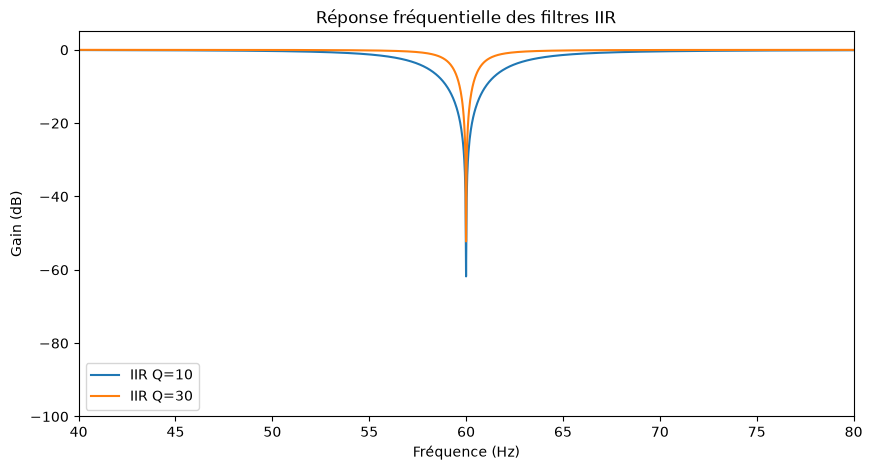

SNR Q=10 : 13.919947761131226 dB
SNR Q=30 : 12.22973235464218 dB
SNR FIR : 14.626456873959262 dB


In [13]:
#exercice2
fs = 500
f0 = 60

# Signal ECG synthétique
t = np.arange(0, 8, 1/fs)

def fake_ecg(t):
    x = np.zeros_like(t)

    for k in range(int(t[-1]/0.8)):
        t0 = k*0.8
        x += 1.00*np.exp(-((t-t0-0.20)/0.015)**2)
        x += 0.15*np.exp(-((t-t0-0.10)/0.050)**2)
        x += 0.25*np.exp(-((t-t0-0.35)/0.060)**2)

    return x

ecg_clean = fake_ecg(t)
ecg_noisy = ecg_clean + 0.4*np.sin(2*np.pi*60*t) + 0.03*np.random.randn(len(t))

# Filtres IIR Q=10 et Q=30
b10, a10 = signal.iirnotch(f0, Q=10, fs=fs)
b30, a30 = signal.iirnotch(f0, Q=30, fs=fs)

y10 = signal.lfilter(b10, a10, ecg_noisy)
y30 = signal.lfilter(b30, a30, ecg_noisy)

# Filtre FIR
N_fir = 401

freqs = [0, 55, 58, 62, 65, fs/2]
gains = [1, 1, 0, 0, 1, 1]

h_fir = signal.firwin2(
    N_fir, freqs, gains,
    fs=fs, window='blackman'
)

y_fir = signal.filtfilt(h_fir, [1], ecg_noisy)

print("Ordre IIR :", 2)
print("Ordre FIR :", N_fir-1)

# Comparaison temporelle
plt.figure(figsize=(12, 5))

plt.plot(t, ecg_noisy, alpha=0.3, label="ECG bruité")
plt.plot(t, y10, label="IIR Q=10")
plt.plot(t, y30, label="IIR Q=30")
plt.plot(t, y_fir, label="FIR")

plt.xlim(0, 2)
plt.title("Comparaison des filtres Notch 60 Hz")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# Réponses fréquentielles
plt.figure(figsize=(10, 5))

for b, a, name in [
    (b10, a10, "IIR Q=10"),
    (b30, a30, "IIR Q=30")
]:
    f, H = signal.freqz(b, a, worN=8192, fs=fs)
    plt.plot(f, 20*np.log10(np.abs(H)+1e-12), label=name)

plt.xlim(40, 80)
plt.ylim(-100, 5)
plt.title("Réponse fréquentielle des filtres IIR")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.legend()
plt.grid()
plt.show()

# SNR
def calcul_snr(reference, output):
    return 10*np.log10(
        np.sum(reference**2) /
        (np.sum((reference-output)**2)+1e-12)
    )

print("SNR Q=10 :", calcul_snr(ecg_clean, y10), "dB")
print("SNR Q=30 :", calcul_snr(ecg_clean, y30), "dB")
print("SNR FIR :", calcul_snr(ecg_clean, y_fir), "dB")

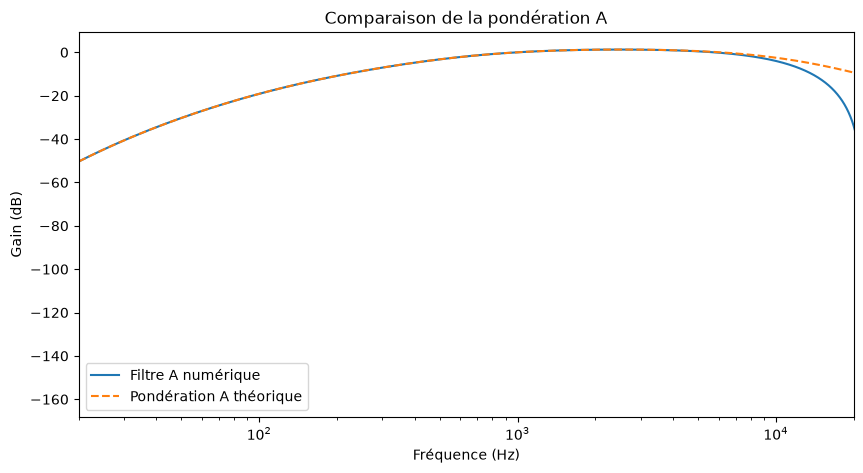

Fichier audio_test.wav introuvable.


In [14]:
#exercice3
fs = 44100

# Fréquences caractéristiques
f1 = 20.598997
f2 = 107.65265
f3 = 737.86223
f4 = 12194.217

w1 = 2*np.pi*f1
w2 = 2*np.pi*f2
w3 = 2*np.pi*f3
w4 = 2*np.pi*f4

# Fonction de transfert analogique
den = np.polymul([1, 2*w1, w1**2], [1, w2])
den = np.polymul(den, [1, w3])
den = np.polymul(den, [1, 2*w4, w4**2])

# Normalisation à 1 kHz
w_1k = 2*np.pi*1000
K = abs(np.polyval(den, 1j*w_1k)) / (w_1k**4)

num = K*np.array([1, 0, 0, 0, 0])

# Transformation bilinéaire
b, a = signal.bilinear(num, den, fs=fs)

# Réponse fréquentielle
f, H = signal.freqz(b, a, worN=8192, fs=fs)

plt.figure(figsize=(10, 5))
plt.semilogx(f, 20*np.log10(np.abs(H)+1e-12),
             label="Filtre A numérique")

# Courbe théorique A
ft = np.logspace(np.log10(20), np.log10(20000), 1000)

Ra = ((12200**2 * ft**4) /
      ((ft**2 + 20.6**2) *
       np.sqrt((ft**2 + 107.7**2)*(ft**2 + 737.9**2)) *
       (ft**2 + 12200**2)))

A_theorique = 20*np.log10(Ra) + 2.0

plt.semilogx(ft, A_theorique, '--',
             label="Pondération A théorique")

plt.title("Comparaison de la pondération A")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.xlim(20, 20000)
plt.legend()
plt.grid()
plt.show()

# Lecture du fichier WAV
audio_file = "audio_test.wav"

if os.path.exists(audio_file):

    fs_audio, x = wavfile.read(audio_file)

    if x.ndim > 1:
        x = x.mean(axis=1)

    if np.issubdtype(x.dtype, np.integer):
        x = x.astype(float) / max(abs(np.iinfo(x.dtype).min),
                                  np.iinfo(x.dtype).max)
    else:
        x = x.astype(float)

    if fs_audio != fs:
        raise ValueError("La fréquence du fichier doit être 44100 Hz.")

    y = signal.lfilter(b, a, x)

    rms = np.sqrt(np.mean(y**2))
    Leq = 20*np.log10(rms + 1e-12)

    print("Niveau sonore équivalent :", Leq, "dBFS")

else:
    print("Fichier audio_test.wav introuvable.")

Taille des blocs : 128
Erreur maximale : 0.0
Absence de discontinuité : True
Latence à 1 kHz : 0.011099312217652443 ms


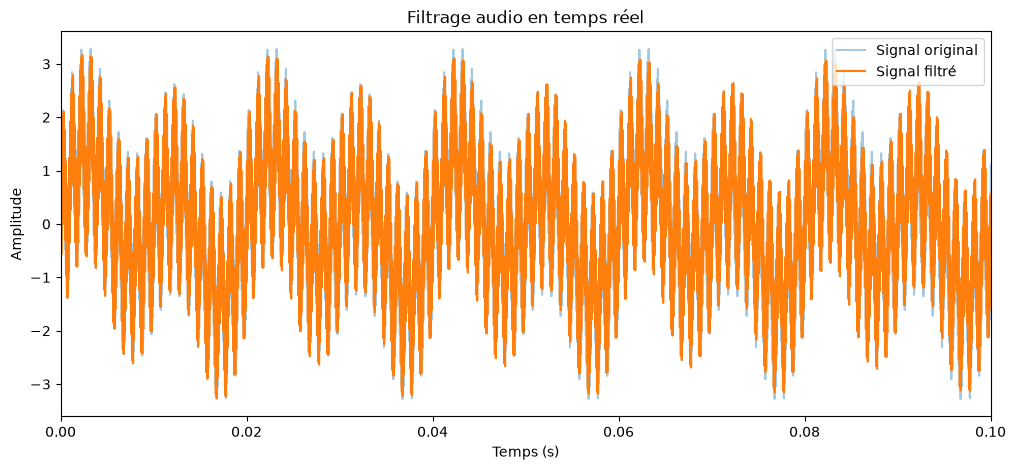

In [15]:
#exercice4
fs = 48000
duration = 2

t = np.arange(0, duration, 1/fs)

# Signal composé
x = (
    np.sin(2*np.pi*100*t)
    + np.sin(2*np.pi*1000*t)
    + np.sin(2*np.pi*10000*t)
    + 0.5*np.sin(2*np.pi*50*t)
)

# Filtre Notch 50 Hz
b_notch, a_notch = signal.iirnotch(50, Q=30, fs=fs)

# Filtre passe-bas 20 kHz
b_lp, a_lp = signal.butter(
    6, 20000,
    btype='lowpass',
    fs=fs
)

# Traitement par blocs
block_size = 128

zi_notch = np.zeros(max(len(a_notch), len(b_notch))-1)
zi_lp = np.zeros(max(len(a_lp), len(b_lp))-1)

y = np.zeros_like(x)

for i in range(0, len(x), block_size):

    block = x[i:i+block_size]

    # Notch
    block, zi_notch = signal.lfilter(
        b_notch, a_notch, block, zi=zi_notch
    )

    # Passe-bas
    block, zi_lp = signal.lfilter(
        b_lp, a_lp, block, zi=zi_lp
    )

    y[i:i+len(block)] = block

# Référence : filtrage en un seul bloc
y_ref = signal.lfilter(b_notch, a_notch, x)
y_ref = signal.lfilter(b_lp, a_lp, y_ref)

# Vérification des discontinuités
error = np.max(np.abs(y-y_ref))

print("Taille des blocs :", block_size)
print("Erreur maximale :", error)
print("Absence de discontinuité :", error < 1e-10)

# Calcul de la latence à 1 kHz
b_total = np.convolve(b_notch, b_lp)
a_total = np.convolve(a_notch, a_lp)

_, gd = signal.group_delay(
    (b_total, a_total),
    w=[2*np.pi*1000/fs]
)

latence = gd[0]/fs

print("Latence à 1 kHz :", latence*1000, "ms")

# Affichage
plt.figure(figsize=(12, 5))

plt.plot(t, x, alpha=0.4, label="Signal original")
plt.plot(t, y, label="Signal filtré")

plt.xlim(0, 0.1)
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.title("Filtrage audio en temps réel")
plt.legend()
plt.grid()
plt.show()

Ordre FIR : 74
Ordre IIR : 5


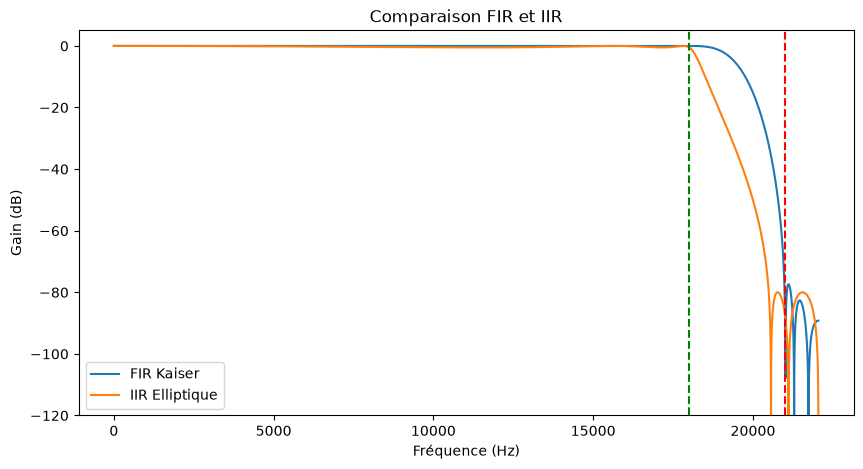

Temps FIR : 0.15263359993696213 s
Temps IIR : 0.0400183005258441 s
Rapport FIR/IIR : 3.8140949998211515
Latence FIR : 0.8390022675736961 ms
Latence IIR à 1 kHz : 0.013535632117247964 ms

Conclusion :
Le filtre IIR présente un ordre plus faible et un coût CPU réduit.
Le filtre FIR garantit une phase linéaire.
Le FIR est indispensable lorsque la conservation de la forme
du signal et la phase linéaire sont prioritaires.


In [16]:
#exercice5
fs = 44100
fp = 18000
fst = 21000
Ap = 0.5
As = 80

# ==================================
# FIR Kaiser
# ==================================

width = (fst-fp)/(fs/2)

N_fir, beta = signal.kaiserord(As, width)

if N_fir % 2 == 0:
    N_fir += 1

h_fir = signal.firwin(
    N_fir,
    (fp+fst)/2,
    window=('kaiser', beta),
    fs=fs
)

print("Ordre FIR :", N_fir-1)

# ==================================
# IIR Elliptique
# ==================================

N_iir, Wn = signal.ellipord(
    fp, fst, Ap, As, fs=fs
)

sos_iir = signal.ellip(
    N_iir, Ap, As, Wn,
    btype='lowpass',
    fs=fs,
    output='sos'
)

print("Ordre IIR :", N_iir)

# ==================================
# Réponses fréquentielles
# ==================================

f, H_fir = signal.freqz(h_fir, worN=8192, fs=fs)
f, H_iir = signal.sosfreqz(sos_iir, worN=8192, fs=fs)

plt.figure(figsize=(10, 5))

plt.plot(f, 20*np.log10(np.abs(H_fir)+1e-12),
         label="FIR Kaiser")

plt.plot(f, 20*np.log10(np.abs(H_iir)+1e-12),
         label="IIR Elliptique")

plt.axvline(fp, color='green', linestyle='--')
plt.axvline(fst, color='red', linestyle='--')

plt.title("Comparaison FIR et IIR")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.ylim(-120, 5)
plt.legend()
plt.grid()
plt.show()

# ==================================
# Mesure du temps CPU
# ==================================

x = np.random.randn(44100)

repetitions = 100

time_fir = timeit.timeit(
    lambda: signal.lfilter(h_fir, [1], x),
    number=repetitions
)

time_iir = timeit.timeit(
    lambda: signal.sosfilt(sos_iir, x),
    number=repetitions
)

print("Temps FIR :", time_fir, "s")
print("Temps IIR :", time_iir, "s")
print("Rapport FIR/IIR :", time_fir/time_iir)

# ==================================
# Latence
# ==================================

latence_fir = (N_fir-1)/(2*fs)

b_iir, a_iir = signal.sos2tf(sos_iir)

_, gd_iir = signal.group_delay(
    (b_iir, a_iir),
    w=[2*np.pi*1000/fs]
)

latence_iir = gd_iir[0]/fs

print("Latence FIR :", latence_fir*1000, "ms")
print("Latence IIR à 1 kHz :", latence_iir*1000, "ms")

# ==================================
# Conclusion
# ==================================

print("\nConclusion :")
print("Le filtre IIR présente un ordre plus faible et un coût CPU réduit.")
print("Le filtre FIR garantit une phase linéaire.")
print("Le FIR est indispensable lorsque la conservation de la forme")
print("du signal et la phase linéaire sont prioritaires.")

# 8. Exercices — Semaine 9

Les exercices étendent les **cas pratiques** vus en séance. Chacun est **autonome** et **vérifiable**.

## Exercice 1 — Butterworth passe-bas : ordre vs précision
Concevoir un passe-bas Butterworth $f_c = 1$ kHz, $f_s = 8$ kHz, $A_s \geq 40$ dB à 2 kHz.
1. Calculer l'ordre nécessaire avec `buttord`.
2. Tracer la réponse en fréquence et la position des pôles.
3. Comparer avec un Chebyshev II de même gabarit (ordre plus faible ?).

## Exercice 2 — Notch 60 Hz pour ECG américain
Reprendre le cas n°2 avec $f_0 = 60$ Hz (réseau US).
1. Recalculer l'ordre IIR et FIR nécessaires.
2. Vérifier la distorsion des QRS avec un `iirnotch` Q=10 vs Q=30.
3. Conclure sur le meilleur compromis temps réel / précision.

## Exercice 3 — Filtre de pondération A (audio psychoacoustique)
La norme IEC 61672 définit la courbe de **pondération A** (sensation auditive).
1. Concevoir un filtre IIR (bilinéaire) qui reproduit cette courbe.
2. Tracer la réponse en fréquence et la comparer à la courbe théorique.
3. Utiliser ce filtre pour calculer un **niveau sonore équivalent** sur un WAV.

## Exercice 4 — Filtre temps réel : boucle complète
Implémenter un pipeline audio complet :
1. Générer un signal à 48 kHz avec plusieurs sinusoïdes (100 Hz, 1 kHz, 10 kHz, 50 Hz parasite).
2. Filtrer **par blocs de 128 échantillons** avec `lfilter` stateful :
   - notch 50 Hz
   - passe-bas 20 kHz
3. Mesurer la latence introduite.
4. Vérifier qu'il n'y a **aucune discontinuité** aux frontières de blocs.

## Exercice 5 — Comparaison FIR vs IIR sur un même gabarit (rappel W8)
Reprendre le gabarit anti-repliement du cas n°1 :
1. Calculer l'ordre FIR Kaiser nécessaire (rappel W8).
2. Calculer l'ordre IIR elliptique nécessaire.
3. Mesurer le coût CPU réel avec `timeit`.
4. Estimer la latence et conclure sur **le seul cas** où le FIR reste indispensable.

# 9. Livrable Semaine 9

- **Remplir** les cellules de code des exercices.
- **Répondre** aux questions théoriques dans les cellules markdown.
- **Commenter** les courbes obtenues (atténuation, phase, distorsion).
- **Rendre** le notebook complet avec toutes les cellules exécutées (`Kernel → Restart & Run All`).

## Grille d'évaluation indicative

| Critère | Poids |
|---|---|
| Fonctionnalité du code | 30 % |
| Réponses aux exercices (résultats numériques) | 30 % |
| Interprétation (famille, ordre, stabilité) | 25 % |
| Qualité des figures et commentaires | 15 % |

---

## 📎 Annexe — Liens vers les autres semaines

- **Semaine 5** : TZ, DC blocker (IIR ordre 1, forme directe).
- **Semaine 8** : conception FIR, fenêtres, phase linéaire, Hilbert.
- **Semaine 9** (ce notebook) : conception IIR, bilinéaire, 4 familles, temps réel.
- **Semaine 10** : **structures d'implémentation** — pourquoi et comment passer à la cascade SOS pour tout ce qui précède.
- **Semaine 11+** : filtres adaptatifs (LMS, RLS), multirate, filtres 2D avancés.

## 📊 Récapitulatif de la trilogie W8 – W9 – W10

| Semaine | Question | Réponse |
|---|---|---|
| **W8** | Comment obtenir une phase linéaire ? | FIR (fenêtres, Hilbert) |
| **W9** | Comment minimiser l'ordre pour un même gabarit ? | IIR (bilinéaire, 4 familles) |
| **W10** | Comment implémenter sans instabilité numérique ? | Cascade SOS, quantification |